### Importando Bibliotecas e Lendo Arquivo

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import os
from numpy.fft import fft, fftshift, fftfreq  # bibliotecas usadas para cálculo numérico, gráficos e operações de ficheiro/FFT.

# Ajustar os gráficos no notebook
%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (12, 4),
    'axes.grid': True
})  

filename = '../ds2.bin'  # diretório do arquivo .bin
fs = 25_000_000          # taxa de amostragem
bytes_per_sample = 4     # 2 bytes I (parte real) + 2 bytes Q (parte imaginária) (int16)

# Configurando o tempo da Janela de Observação
t_start = 60.0
t_end   = 300.0  # Mesmo intervalo do codev2 para comparação correta
# n_pontos = 1000 # numeros de amostras

# cria o espaço entre amostras
# tempos_simples = np.linspace(t_start, t_end, n_pontos)

# Lendo informações sobre o arquivo
total_bytes = os.path.getsize(filename) # tamanho do arquivo em bytes
N_int16 = total_bytes // 2              # quantidade de int16 no arquivo (cada int16 são 2 bytes)
N_samples = total_bytes // bytes_per_sample  # num de amostras complecas (I,Q) cada uma tem 4 bytes
print(f'Arquivo: {filename}\n- Tamanho: {total_bytes:,} bytes\n- Amostras complexas: {N_samples:,}\n- Duração aprox: {N_samples/fs:.2f} s')

# abre o arquino na mem mapeada sem carregar tudo na RAM (lê fatias)
mm = np.memmap(filename, dtype=np.int16, mode='r', shape=(N_int16,))

# Função para extrair uma janela em um determinado tempo
def read_window_at_time(t_sec: float, win_N: int) -> np.ndarray:
    #t_sec é o tempo em seg no centro da janela
    ctr = int(t_sec * fs) # índice da amostra central da janela de win_N amostras
    half = win_N // 2
    start = max(0, ctr - half) # max(0,...) evita amostras com indices negativos (nao existem no dataset)
    end = min(N_samples, start + win_N) 
    # garantir comprimento exato quando estamos próximos das bordas do arquivo
    start = max(0, end - win_N) # garantir que a janela vai ter o num certo de amostras
    i0 = 2 * start 
    i1 = 2 * end
    seg = mm[i0:i1]
    I = seg[0::2].astype(np.float32) # pega todos os componentes pares
    Q = seg[1::2].astype(np.float32) # pega todos os componentes impares
    return I + 1j * Q # vetor completo (float32) com win_N amostras (talvez menos perto das bordas)


Arquivo: ../ds2.bin
- Tamanho: 45,717,913,600 bytes
- Amostras complexas: 11,429,478,400
- Duração aprox: 457.18 s


### Análise da Potência 

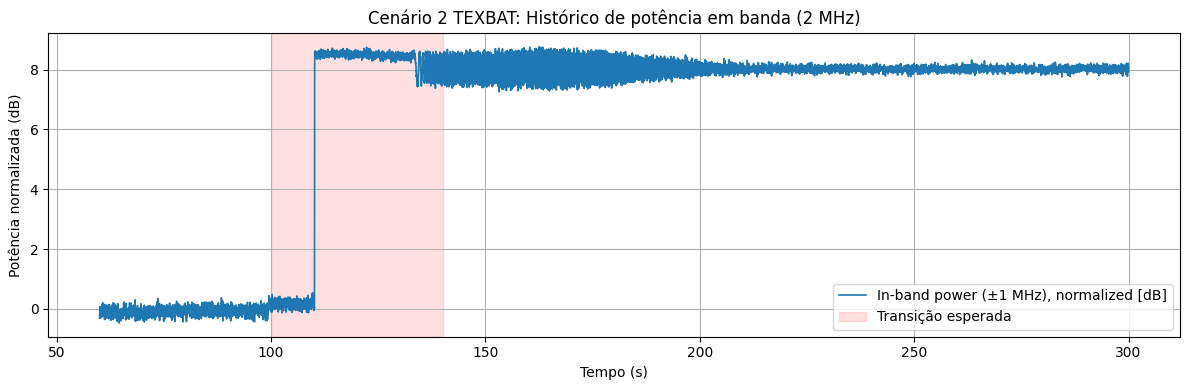

Delta dB (pós - pré): 8.027959503930937 dB


In [42]:
# Potência in‑band (~±1 MHz ao redor de DC)
def inband_power_2mhz(x: np.ndarray) -> tuple[float, float]:
    N = len(x) # tamanho do array de amostras complexas
    # Janela Hann para reduzir vazamento espectral // pega um trecho finito do sinal
    w = np.hanning(N).astype(np.float32) # suaviza bordas
    X = fftshift(fft(x * w)) # calcula a tansformada de fourier para o trecho da janela 
    freqs = fftshift(fftfreq(N, d=1/fs))  # Transformar para frequencia
    mask = np.abs(freqs) <= 1_000_000.0  # ±1 MHz
    # PSD aproximada: |X|^2; integra apenas os bins selecionados e normaliza pela energia da janela
    p_lin = float(np.sum(np.abs(X[mask])**2) / np.sum(w**2)) # potencia linear
    p_db = 10.0 * np.log10(p_lin + 1e-20) # potencia em db
    return p_lin, p_db

n_points = 10000 # num de centros (ctr) de janelas
win_N = 32768  # tam da janela -> 2^15 ≈ 1.31 ms a 25 Msps 
T = np.linspace(t_start, t_end, n_points) # array com o ctr de cada janela [n_points]


power_lin = np.empty(n_points, dtype=np.float64)
power_db = np.empty(n_points, dtype=np.float64)


# para cada tempo, ler janela e estimar potência em banda (±1 MHz)
for i, t in enumerate(T):
    # read_window_at_time: lê win_N amostras complexas centradas em 't' (I + 1j*Q)
    x = read_window_at_time(float(t), win_N)
    # inband_power_2mhz: aplica Hann+FFT e integra |X|^2 apenas nos bins |f| <= 1 MHz
    p_lin, p_db = inband_power_2mhz(x)
    # Armazenar resultados (potência linear e dB) para uso posterior
    power_lin[i] = p_lin
    power_db[i] = p_db

# Normalizar potência ao nível pré-ataque
pre_mask = T < 120.0  # janela considerada 'antes do ataque'
# Calcula a mediana das potências pré‑ataque como nível de referência 
baseline = np.median(power_lin[pre_mask]) if np.any(pre_mask) else np.median(power_lin)
# Converter razão linear -> dB para visualização (adiciona pequena constante para estabilidade numérica)
power_norm_db = 10.0 * np.log10((power_lin / (baseline + 1e-30)) + 1e-30)

# Plot: potência normalizada ao longo do tempo
fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.plot(T, power_norm_db, '-', lw=1.2, label='In-band power (±1 MHz), normalized [dB]')
# Marca a janela esperada de transição (120–140 s) para referência visual
ax.axvspan(100, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Potência normalizada (dB)')
ax.set_title('Cenário 2 TEXBAT: Histórico de potência em banda (2 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

# Estatística rápida: diferença de mediana pós- vs pré-janela de transição (indicador de overpower)
print('Delta dB (pós - pré):', float(np.median(power_norm_db[T>140]) - np.median(power_norm_db[T<120])), 'dB')

### Análise C/N0 (Canais Falsos)

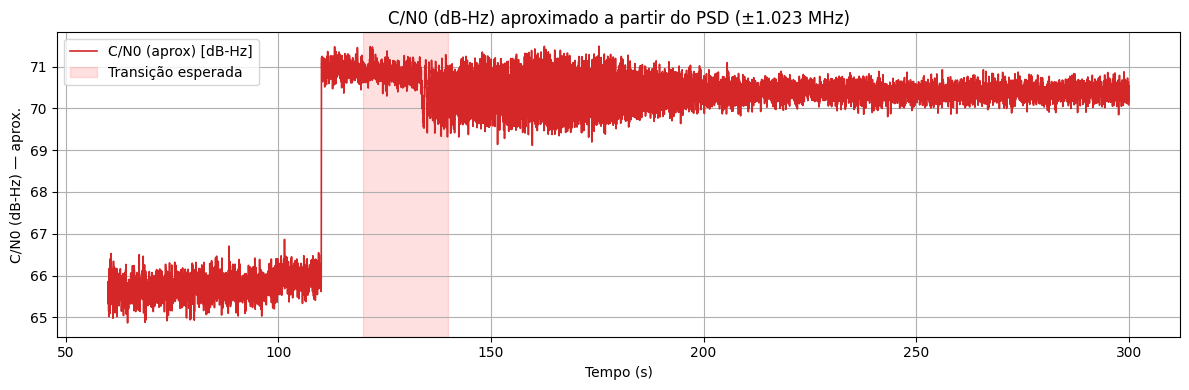

C/N0 pré (mediana, t<120s):  65.83380530671366 dB-Hz
C/N0 pós (mediana, t>140s):  70.40139578177636 dB-Hz
Δ (pós - pré):  4.567590475062701 dB-Hz


In [43]:
# 5) C/N0 (dB-Hz) — estimativa por PSD (sem despreading)
# Atenção: é uma aproximação de tendência (não absoluta), baseada em:
# - Centro espectral (fc) por centróide em ±2 MHz
# - Banda do sinal: ±1.023 MHz
# - N0 estimado nas bandas de ruído: 1.5–3.5 MHz (ambos os lados)
# Fórmula: C/N0 ≈ (P_band - N0 * B_sig) / N0  [Hz]  → 10*log10(·) em dB-Hz

win_N_cn0 = 32768  # mesmo tamanho de janela
B_sig = 2 * 1.023e6

def estimate_cn0_dbhz(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    f = fftshift(fftfreq(N, d=1/fs))
    # Periodograma (dois lados) por Hz
    S = (np.abs(X)**2) / (fs * np.sum(w**2))
    df = f[1] - f[0]

    # Estimar fc pelo centróide em ±2 MHz
    band2 = np.abs(f) <= 2.0e6
    S2 = S[band2]
    f2 = f[band2]
    denom = np.sum(S2) + 1e-30
    fc = float(np.sum(f2 * S2) / denom)

    # Máscaras de banda do sinal e bandas de ruído
    sig_mask = np.abs(f - fc) <= 1.023e6
    noise_mask = (np.abs(f - fc) >= 1.5e6) & (np.abs(f - fc) <= 3.5e6)

    # N0 por mediana (robusto)
    if not np.any(noise_mask):
        return np.nan
    N0 = float(np.median(S[noise_mask]))

    # Potência integrada na banda do sinal
    P_band = float(np.sum(S[sig_mask]) * df)

    # C estimado e C/N0
    C_est = max(P_band - N0 * B_sig, 1e-30)
    CNo = C_est / (N0 + 1e-30)  # Hz
    return 10.0 * np.log10(CNo)

CNo_dbHz = np.empty_like(T)
for i, t in enumerate(T):
    x = read_window_at_time(float(t), win_N_cn0)
    CNo_dbHz[i] = estimate_cn0_dbhz(x)

fig, ax = plt.subplots(1,1, figsize=(12,4))
ax.plot(T, CNo_dbHz, '-', lw=1.2, color='C3', label='C/N0 (aprox) [dB-Hz]')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('C/N0 (dB-Hz) — aprox.')
ax.set_title('C/N0 (dB-Hz) aproximado a partir do PSD (±1.023 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

print('C/N0 pré (mediana, t<120s): ', float(np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')
print('C/N0 pós (mediana, t>140s): ', float(np.nanmedian(CNo_dbHz[T>140])), 'dB-Hz')
print('Δ (pós - pré): ', float(np.nanmedian(CNo_dbHz[T>140]) - np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')

### Códigos de Teste

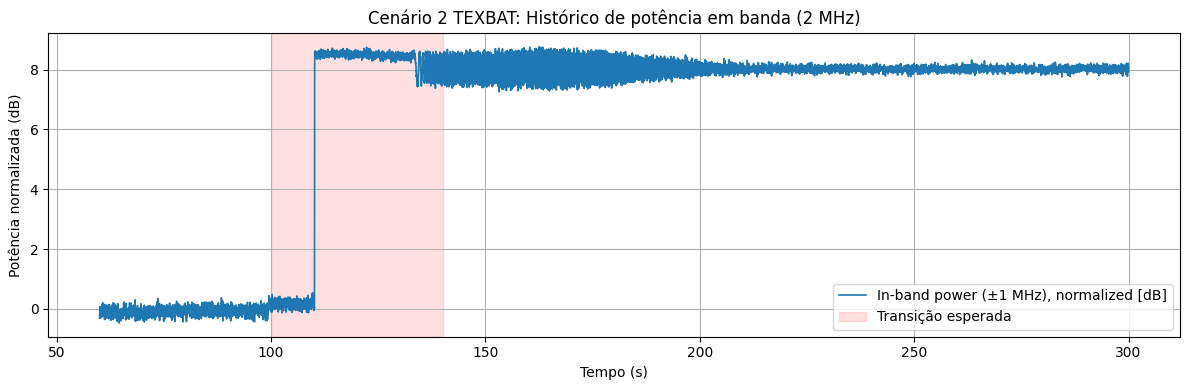

Delta dB (pós - pré): 8.027959503930937 dB


In [44]:

# np.random.seed(0)  

n_points = 10000 # num de pontos em T

win_N = 32768  # tam da janela -> 2^15 ≈ 1.31 ms a 25 Msps 

T = np.linspace(t_start, t_end, n_points) # array com o ctr de cada janela


power_lin = np.empty(n_points, dtype=np.float64)
power_db = np.empty(n_points, dtype=np.float64)
# centroid_hz = np.empty(n_points, dtype=np.float64)
# phi_lag1 = np.empty(n_points, dtype=np.float64)

# para cada tempo, ler janela e estimar potência em banda (±1 MHz)
for i, t in enumerate(T):
    # read_window_at_time: lê win_N amostras complexas centradas em 't' (I + 1j*Q)
    x = read_window_at_time(float(t), win_N)
    # inband_power_2mhz: aplica Hann+FFT e integra |X|^2 apenas nos bins |f| <= 1 MHz
    p_lin, p_db = inband_power_2mhz(x)
    # Armazenar resultados (potência linear e dB) para uso posterior
    power_lin[i] = p_lin
    power_db[i] = p_db
    # centroid_hz[i] = doppler_proxy_centroid(x)  # proxy de Doppler pela centróide espectral
    # phi_lag1[i] = lag1_autocorr_phase(x)       # proxy de perturbação de fase (lag-1)

# Normalizar potência ao nível pré-ataque (robustamente usando mediana)
pre_mask = T < 120.0  # janela considerada 'antes do ataque'
# Se houver pontos pré-ataque, usar a mediana desses; senão, usar mediana global como fallback
baseline = np.median(power_lin[pre_mask]) if np.any(pre_mask) else np.median(power_lin)
# Converter razão linear -> dB para visualização (adiciona pequena constante para estabilidade numérica)
power_norm_db = 10.0 * np.log10((power_lin / (baseline + 1e-30)) + 1e-30)

# Plot: potência normalizada ao longo do tempo
fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.plot(T, power_norm_db, '-', lw=1.2, label='In-band power (±1 MHz), normalized [dB]')
# Marca a janela esperada de transição (ex.: 120–140 s) para referência visual
ax.axvspan(100, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Potência normalizada (dB)')
ax.set_title('Cenário 2 TEXBAT: Histórico de potência em banda (2 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

# Estatística rápida: diferença de mediana pós- vs pré-janela de transição (indicador de overpower)
print('Delta dB (pós - pré):', float(np.median(power_norm_db[T>140]) - np.median(power_norm_db[T<120])), 'dB')

In [45]:
# Função: doppler_proxy_centroid(x)
# Explicação (PT-BR):
# - Objetivo: fornecer um proxy simples para o deslocamento de frequência (Doppler) no sinal baseband.
# - Procedimento: calcula o centróide espectral na mesma janela ±1 MHz — ou seja, faz uma média ponderada das frequências
#   usando a potência espectral como peso. Resultado em Hz que indica para que lado a energia está deslocada.
def doppler_proxy_centroid(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    freqs = fftshift(fftfreq(N, d=1/fs))
    mask = np.abs(freqs) <= 1_000_000.0
    P = (np.abs(X)**2)[mask]
    F = freqs[mask]
    denom = float(np.sum(P)) + 1e-30
    return float(np.sum(F * P) / denom)

# Função: lag1_autocorr_phase(x)
# Explicação (PT-BR):
# - Objetivo: fornecer um indicador rápido de perturbação de fase (phase trauma) usando correlação de lag-1.
# - Procedimento: normaliza o vetor para potência unitária (para ficar independente da escala), calcula r1 =
#   <x[n]* conj(x[n+1])> (produto interno) e retorna a fase de r1. Mudanças bruscas nessa fase indicam perturbações
#   na portadora (ex.: captura/pull-off durante takeover).
def lag1_autocorr_phase(x: np.ndarray) -> float:
    # Normaliza para potência unitária para ser independente da amplitude absoluta
    if len(x) < 2:
        return 0.0
    xn = x / (np.sqrt(np.mean(np.abs(x)**2)) + 1e-20)
    r1 = np.vdot(xn[:-1], xn[1:]) / (len(xn) - 1)
    return float(np.angle(r1))
